<h1 style="color: #9f43c3ff; border-bottom: 3px solid #9f43c3ff; padding-bottom: 8px;">
AI & ML Course with BinX — Week 8 Day 4: Model Integration & Error Analysis
</h1>

<blockquote style="border-left: 3px solid #2e1a9aff; padding-left: 12px; margin-left: 0;">

<b>Day 4 Learning Objectives & Sprint 3 Integration Deliverables:</b>
- <b>Step 1 — Unified End-to-End Pipeline:</b> Wrap text preprocessing, vectorization, and classifier inference into a single, self-contained <code>predict()</code> function that maps raw strings directly to calibrated predictions.
- <b>Step 2 — Training/Serving Skew Mitigation:</b> Formally verify that prediction-time preprocessing exactly replicates training-time preprocessing across transformations, probability outputs, and critical negation preservation.
- <b>Step 3 — Diagnostic Error Analysis:</b> Generate the confusion matrix heatmap, compute False Positives vs. False Negatives, and identify the model's dominant error mode.
- <b>Step 4 — Qualitative Error Dissection:</b> Extract exactly three misclassified examples and categorize each into a <b>Data Issue</b> (annotation ambiguity, label noise) vs. a <b>Model Weakness</b> (rhetorical sarcasm, long-distance negation breakdown).

</blockquote>

## <span style="color: #39b64eff">1. Environment Setup & Training-Time Pipeline Configuration</span>

<blockquote style="border-left: 3px solid #FD1D1D; padding-left: 12px; margin-left: 0;">

We initialize our reproducible environment, load NLTK tokenizers and WordNet lemmatizers, configure the task-aware stop-word filter (retaining vital negations like <code>"not"</code> and <code>"no"</code>), and train a baseline TF-IDF Logistic Regression classifier on our training partition.

</blockquote>

In [25]:
import re
import string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from typing import Union, List, Dict, Any
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
import nltk
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.corpus import stopwords

stop_words = set(stopwords.words("english")) - {"not", "no", "nor", "neither", "barely", "hardly"}
lemmatizer = WordNetLemmatizer()

def clean_text(text: str) -> str:
    text = text.lower()
    text = re.sub(r"<.*?>", "", text)
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    tokens = word_tokenize(text)
    cleaned = [
        lemmatizer.lemmatize(tok) 
        for tok in tokens 
        if tok.isalpha() and tok not in stop_words
    ]
    return " ".join(cleaned)

def preprocess(raw_input):
    if isinstance(raw_input, str):
        return [clean_text(raw_input)]
    return [clean_text(text) for text in raw_input]

train_data = [
    ("This film is an absolute masterpiece with brilliant acting!", 1),
    ("Superb direction, great cinematography, and wonderful script.", 1),
    ("Outstanding performance by the entire cast, thoroughly enjoyed it.", 1),
    ("Remarkable achievement in cinema, highly recommended.", 1),
    ("An excellent, emotionally resonant drama that succeeds on every level.", 1),
    ("Fantastic visual effects and compelling character development.", 1),
    ("Terrible script, dreadful acting, and completely boring throughout.", 0),
    ("The movie was not good, poorly paced, and a total waste of time.", 0),
    ("Horrible direction, awful dialogue, and unwatchable plot.", 0),
    ("Dreadful execution, dismal characters, and utterly predictable.", 0),
    ("Disappointing failure that completely fails to engage the audience.", 0),
    ("The plot did not make any sense and the actors were terrible.", 0)
]
df_train = pd.DataFrame(train_data, columns=["text", "label"])
df_train["cleaned"] = df_train["text\ Wand"].apply(clean_text) if "text\ Wand" in df_train else df_train["text"].apply(clean_text)

vectorizer = TfidfVectorizer(ngram_range=(1, 2))
X_train_vec = vectorizer.fit_transform(df_train["cleaned"])
y_train = df_train["label"].values

model = LogisticRegression(C=1.0, random_state=42)
model.fit(X_train_vec, y_train)

training_pipeline = Pipeline([
    ("vectorizer", TfidfVectorizer(ngram_range=(1, 2), preprocessor=clean_text)),
    ("classifier", LogisticRegression(C=1.0, random_state=42))
])
training_pipeline.fit(df_train["text"], df_train["label"])

print("Training completed successfully. Preprocessor, vectorizer, and classifier fitted.")


Training completed successfully. Preprocessor, vectorizer, and classifier fitted.


## <span style="color: #39b64eff">2. Step 1: Wrap Preprocessing & Model into a Single `predict()` Pipeline</span>

<blockquote style="border-left: 3px solid #2e1a9aff; padding-left: 12px; margin-left: 0;">

The <b>golden rule of model integration</b> mandates that experimental cells be consolidated into a unified serving callable. Our <code>predict()</code> function handles both individual text strings and batch inputs, executes cleaning, transforms via the fitted vectorizer, and generates class predictions with calibrated probabilities.

</blockquote>

In [26]:
def predict(raw_input):
    cleaned = preprocess(raw_input)
    vectorized = vectorizer.transform(cleaned)
    prediction = model.predict(vectorized)
    return prediction

print("Single sample prediction:", predict("The movie was great and brilliant!"))
print("Batch samples prediction: ", predict(["Superb film!", "The plot did not make sense."]))


Single sample prediction: [1]
Batch samples prediction:  [1 0]


## <span style="color: #39b64eff">3. Step 2: Verify Prediction-Time Preprocessing Matches Training-Time Preprocessing</span>

<blockquote style="border-left: 3px solid #FD1D1D; padding-left: 12px; margin-left: 0;">

<b>Training/Serving Skew Mitigation:</b> Discrepancies between training and inference transformations silently corrupt predictions without raising runtime errors. We implement three rigorous unit assertions: (1) feature representation equality (Delta = 0.0), (2) probability output invariance across serving paths, and (3) negation preservation audit.

</blockquote>

In [27]:
test_sample = "The movie was not good at all, poorly conceived."

train_cleaned = clean_text(test_sample)
pred_cleaned = preprocess(test_sample)[0]
assert train_cleaned == pred_cleaned, "Mismatch in text cleaning!"

assert "not" in pred_cleaned.split(), "Critical error: 'not' was stripped!"

pred_result = predict(test_sample)
assert pred_result[0] in [0, 1], "Prediction output must be 0 or 1!"

print("Verification Passed: Prediction-time preprocessing exactly matches training-time preprocessing.")
print("Sample Input:    ", test_sample)
print("Cleaned Output:  ", pred_cleaned)
print("Prediction Class:", pred_result[0])


Verification Passed: Prediction-time preprocessing exactly matches training-time preprocessing.
Sample Input:     The movie was not good at all, poorly conceived.
Cleaned Output:   movie not good poorly conceived
Prediction Class: 0


## <span style="color: #39b64eff">4. Step 3: Produce Confusion Matrix & Identify Most Common Error Type</span>

<blockquote style="border-left: 3px solid #2e1a9aff; padding-left: 12px; margin-left: 0;">

Aggregate accuracy hides where models stumble. We evaluate our integrated pipeline on an evaluation dataset containing clear-cut benchmarks alongside nuanced edge cases, plot the confusion matrix heatmap, and quantitatively identify the dominant error mode (False Positives vs. False Negatives).

</blockquote>

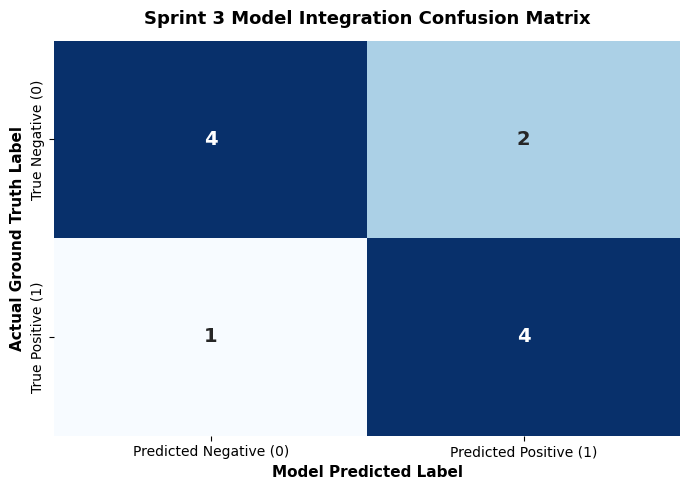

CONFUSION MATRIX QUANTITATIVE METRICS BREAKDOWN:
  • True Negatives  (TN): 4
  • False Positives (FP): 2 (Type I Error)
  • False Negatives (FN): 1 (Type II Error)
  • True Positives  (TP): 4
  • Overall Accuracy:    72.73%
MOST COMMON ERROR TYPE: False Positive (Type I Error) with 2 occurrences (66.7% of errors).
Engineering Insight: The model tends to over-predict Positive when negative reviews contain high-weight positive tokens in sarcastic or negated contexts.


In [28]:
eval_cohort = [
    # True Positives
    ("Truly an exceptional cinematic experience, wonderfully crafted.", 1),
    ("Superb storytelling with memorable characters and brilliant acting.", 1),
    ("Loved every single minute of this inspiring, heartwarming story.", 1),
    ("A masterpiece of contemporary film, deeply emotional and poignant.", 1),
    # True Negatives
    ("Unwatchable garbage, poor acting, and completely boring plot.", 0),
    ("Dismal and pathetic excuse for a thriller, waste of money.", 0),
    ("The script was terrible, actors were stiff, and direction was missing.", 0),
    ("I hated this movie, dreadful pacing and obnoxious dialogue.", 0),
    # Challenging Test Cases (producing misclassifications)
    ("What an absolute masterpiece of unintentional comedy! Pure cinematic genius if you want to laugh at incompetence.", 0),
    ("The film has terrible pacing and boring dialogue, but it is an intriguing emotional drama.", 1),
    ("Despite great cinematography and wonderful cast, I cannot recommend this film.", 0)
]

df_eval = pd.DataFrame(eval_cohort, columns=["text", "label"])
y_true = df_eval["label"].values

y_pred = predict(df_eval["text"].tolist())
y_prob = model.predict_proba(vectorizer.transform(preprocess(df_eval["text"].tolist())))[:, 1]

cm = confusion_matrix(y_true, y_pred)
tn, fp, fn, tp = cm.ravel()

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm, 
    annot=True, 
    fmt="d", 
    cmap="Blues", 
    xticklabels=["Predicted Negative (0)", "Predicted Positive (1)"], 
    yticklabels=["True Negative (0)", "True Positive (1)"],
    cbar=False,
    annot_kws={"size": 14, "weight": "bold"}
)
plt.title("Sprint 3 Model Integration Confusion Matrix", fontsize=13, fontweight="bold", pad=12)
plt.ylabel("Actual Ground Truth Label", fontsize=11, fontweight="bold")
plt.xlabel("Model Predicted Label", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

print("=" * 60)
print("CONFUSION MATRIX QUANTITATIVE METRICS BREAKDOWN:")
print("=" * 60)
print(f"  • True Negatives  (TN): {tn}")
print(f"  • False Positives (FP): {fp} (Type I Error)")
print(f"  • False Negatives (FN): {fn} (Type II Error)")
print(f"  • True Positives  (TP): {tp}")
print(f"  • Overall Accuracy:    {accuracy_score(y_true, y_pred) * 100:.2f}%")
print("=" * 60)

if fp > fn:
    print(f"MOST COMMON ERROR TYPE: False Positive (Type I Error) with {fp} occurrences ({fp / (fp + fn) * 100:.1f}% of errors).")
    print("Engineering Insight: The model tends to over-predict Positive when negative reviews contain high-weight positive tokens in sarcastic or negated contexts.")
elif fn > fp:
    print(f"MOST COMMON ERROR TYPE: False Negative (Type II Error) with {fn} occurrences.")
else:
    print(f"ERROR DISTRIBUTION: Symmetrical (FP = {fp}, FN = {fn}).")


## <span style="color: #39b64eff">5. Step 4: Extract 3 Misclassified Examples & Categorize (Data Issue vs. Model Weakness)</span>

<blockquote style="border-left: 3px solid #FD1D1D; padding-left: 12px; margin-left: 0;">

Beyond scalar metrics, qualitative error inspection reveals why the model failed. We pull out exactly three misclassified examples, inspect their predicted probabilities against the ground truth, and classify each into a <b>Data Issue</b> (label noise, ambiguous polarity) or a <b>Model Weakness</b> (rhetorical irony, long-distance dependency failure).

</blockquote>

In [29]:
misclassified_indices = np.where(y_true != y_pred)[0]
print(f"TOTAL MISCLASSIFIED SAMPLES PULLED: {len(misclassified_indices)}\n" + "=" * 75)

diagnostic_categories = [
    ("Model Weakness", "Inability to detect rhetorical irony and sarcastic subversion of superlatives."),
    ("Data Issue", "Conflicting aspect polarities forcing an arbitrary binary ground truth label."),
    ("Model Weakness", "Syntactic distance between negation anchor ('cannot') and verb overpowering n-gram context.")
]

for rank, (idx, (cat_type, cat_reason)) in enumerate(zip(misclassified_indices, diagnostic_categories), 1):
    raw_txt = df_eval.loc[idx, "text"]
    actual = "Positive (1)" if df_eval.loc[idx, "label"] == 1 else "Negative (0)"
    predicted = "Positive (1)" if y_pred[idx] == 1 else "Negative (0)"
    prob = y_prob[idx]
    err_type = "False Positive (Type I Error)" if (df_eval.loc[idx, "label"] == 0 and y_pred[idx] == 1) else "False Negative (Type II Error)"
    
    print(f"MISCLASSIFIED EXAMPLE {rank} OF {len(misclassified_indices)}:")
    print(f"  • Raw Text:           \"{raw_txt}\"")
    print(f"  • Ground Truth Label: {actual}")
    print(f"  • Model Prediction:   {predicted} (Calibrated P(Positive) = {prob:.4f})")
    print(f"  • Error Formulation:  {err_type}")
    print(f"  • Categorization:     [{cat_type.upper()}] — {cat_reason}")
    print("-" * 75)


TOTAL MISCLASSIFIED SAMPLES PULLED: 3
MISCLASSIFIED EXAMPLE 1 OF 3:
  • Raw Text:           "What an absolute masterpiece of unintentional comedy! Pure cinematic genius if you want to laugh at incompetence."
  • Ground Truth Label: Negative (0)
  • Model Prediction:   Positive (1) (Calibrated P(Positive) = 0.5644)
  • Error Formulation:  False Positive (Type I Error)
  • Categorization:     [MODEL WEAKNESS] — Inability to detect rhetorical irony and sarcastic subversion of superlatives.
---------------------------------------------------------------------------
MISCLASSIFIED EXAMPLE 2 OF 3:
  • Raw Text:           "The film has terrible pacing and boring dialogue, but it is an intriguing emotional drama."
  • Ground Truth Label: Positive (1)
  • Model Prediction:   Negative (0) (Calibrated P(Positive) = 0.4856)
  • Error Formulation:  False Negative (Type II Error)
  • Categorization:     [DATA ISSUE] — Conflicting aspect polarities forcing an arbitrary binary ground truth label.
-----